# 08 - Decision-Making: From Perception to Action

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## The Full Pipeline: Perception -> Prediction -> Planning -> Control

Every notebook up to this point has been building toward one missing piece. Real autonomous systems, like a self-driving car or a humanoid robot, are all structured around some version of this 4-step progress:

1. **Perception** covers what's out there, right now? `02`-`05` built this: object detection, camera pose (intrinsics/extrinsics, PnP), depth recovery, and multi-object tracking (SORT).
2. **Prediction** tells us, where is it going? `06`-`07` built this: trajectory forecasting from a history window, and multi-hypothesis futures when the answer is genuinely ambiguous.
3. **Planning** asks given our predictions, what should *I* do? This notebook.
4. **Control** tells us how do I actually execute that decision with motors? Already built, just in a different primer: `back_end_resources/systems_primer/04_control_loops_pid` (PID) and `04b_motion_control_and_trajectories` (motion profiling, Pure Pursuit).

This is the same architecture a company like Waymo describes its self-driving stack with. Every notebook before this one has been Perception or Prediction. Planning is the layer in between that we will work through in this notebook. 

## Two Match Phases, One Planning Problem

It's tempting to think Planning only matters during the autonomous period of a match, since that's the only time the robot is fully in charge. Planning is relevant in both phases. Any of the planning logic you see is phase-agnostic, with the only change coming from a signal regarding when it is allowed to act. 

For autonomous, planning decides literally everything. Simple enough. 

For teleop, planning decides something narrower: when to step in. A driver is doing most of the work, but vision-assisted behaviors like auto-align are useful if the decision-making behind that feature is correct. 

A system that assists a human driver instead of outright replacing them is known in the autonomous vehical (AV) world as **shared control**. The auto-align feature is specifically known as a **driver-assist** feature. 

## A Vision-Triggered State Machine: Auto-Align

`back_end_resources/systems_primer/03_state_machines` covers how we create state-based tools. It created a tool with states, transitions, and events, using an `Intake -> Transport -> Score -> Idle` example. Auto-align is the same tool pointed at a vision-driven problem.

This type of tool would have 4 states: 

1. **IDLE**: the robot is not currently trying to align. Either the driver hasn't asked, or there is nothing usable in view for the robot to align with.
2. **ALIGNING**: A tag is visible, the driver has requested assist, and the robot is actively driving toward the computed setpoint. 
3. **ALIGNED**: The robot is within the designated tolerance of the target and is ready to score. 
4. **LOST_TRACK**: The robot was aligning, but the tag's confidence dropped (meaning our robot is no longer sure it has a tag in view) or the tag left the frame entirely. This is distinct from `IDLE` because a tag that is gone for a couple of frames because a bumper clipped the camera view shouldn't change the whole behavior. This is the same "coast on the last known state, then correct once new data arrives" idea `05`'s Kalman filter used to survive occlusion, just applied one level up. Instead of coasting a *position estimate* through a gap in detections, we're coasting a *behavior* through a gap in confident detections, with a grace period before giving up and returning control to the driver.

Regardless of the state we are in, a predicted collision should be able to force an immediate abort from any state, no matter how confident the tag detection is. A safety override beats every other rule.

In [2]:
CONF_THRESHOLD = 0.6
DISTANCE_TOLERANCE = 0.05
LOST_TRACK_GRACE_TICKS = 8

class AutoAlignFSM:
    """ A vision-triggered state machine for an auto-align driver-assist behavior. """

    def __init__(self):
        self.state = "IDLE"
        self.lost_ticks = 0

    def step(self, driver_requesting, tag_visible, confidence, distance, collision_risk=False):
        confident = tag_visible and confidence >= CONF_THRESHOLD

        if not driver_requesting:
            self.state, self.lost_ticks = "IDLE", 0
            return self.state

        if collision_risk:
            # a safety override beats every other rule, from any state
            self.state, self.lost_ticks = "IDLE", 0
            return self.state

        if self.state == "IDLE":
            if confident:
                self.state = "ALIGNING"
        elif self.state == "ALIGNING":
            if not confident:
                self.state, self.lost_ticks = "LOST_TRACK", 0
            elif distance <= DISTANCE_TOLERANCE:
                self.state = "ALIGNED"
        elif self.state == "ALIGNED":
            if not confident:
                self.state, self.lost_ticks = "LOST_TRACK", 0
            elif distance > DISTANCE_TOLERANCE:
                self.state = "ALIGNING"
        elif self.state == "LOST_TRACK":
            if confident:
                self.state, self.lost_ticks = "ALIGNING", 0
            else:
                self.lost_ticks += 1
                if self.lost_ticks > LOST_TRACK_GRACE_TICKS:
                    self.state = "IDLE"

        return self.state

Let's simulate a realistic tick sequence. The driver requests assist, the tag is confidently visible and the robot drives itself into tolerance, gets briefly occluded partway through (well within the grace period), recovers, reaches `ALIGNED`, and finally the driver lets go of the request.

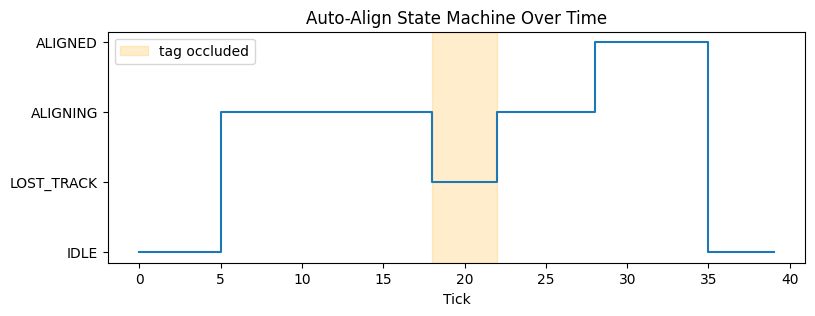

tick  0: -> IDLE
tick  5: -> ALIGNING
tick 18: -> LOST_TRACK
tick 22: -> ALIGNING
tick 28: -> ALIGNED
tick 35: -> IDLE


In [3]:
n_ticks = 40
fsm = AutoAlignFSM()
states = []
for t in range(n_ticks):
    driver_requesting = 5 <= t < 35
    tag_visible = not (18 <= t < 22)          # a brief real occlusion, well inside the grace period
    distance = max(0.5 - 0.02 * max(0, t - 5), 0.0)
    confidence = 0.9 if tag_visible else 0.0
    states.append(fsm.step(driver_requesting, tag_visible, confidence, distance))

state_order = ["IDLE", "LOST_TRACK", "ALIGNING", "ALIGNED"]
state_indices = [state_order.index(s) for s in states]

plt.figure(figsize=(9, 3))
plt.step(range(n_ticks), state_indices, where="post")
plt.yticks(range(len(state_order)), state_order)
plt.axvspan(18, 22, color="orange", alpha=0.2, label="tag occluded")
plt.xlabel("Tick")
plt.title("Auto-Align State Machine Over Time")
plt.legend()
plt.show()

for t, s in enumerate(states):
    if t == 0 or states[t] != states[t - 1]:
        print(f"tick {t:>2}: -> {s}")

The state machine handles the brief occlusion the way `05`'s Kalman filter handled a gap in detections. It doesn't panic and reset to `IDLE` the instant the tag disappears, it coasts in `LOST_TRACK` for a few ticks and recovers cleanly once the tag reappears. There were four ticks of occlusion, well inside the eight-tick grace period. Try extending the occlusion past the grace period in the exercise below and see what changes.

## From Prediction to Decision: Collision-Checking a Candidate Path

`06` and `07` built out forecasting where an opponent robot is headed. In `07`, there was a focus on distinct, probability-weighted futures when the outcome is ambiguous. Nothing in either notebook ever *used* that forecast for anything. Before committing to a candidate action (e.g., driving toward an alignment target, following a generated path) check whether it's likely to collide with where something else is headed.

The steps are as follows. 

1. Take a candidate ego path, which is the sequence of positions the robot would occupy if it executed the plan.
2. For each of the opponent's predicted hypotheses (each with a probability, straight from `07`'s output shape), compute the closest approach between the two paths over the shared time horizon.
3. If the closest approach for a hypothesis is inside a safety radius, that hypothesis represents a collision.
4. Sum the probabilities of every colliding hypothesis into an **expected collision probability**, which is a single number a planner can threshold against.

This directly answers "should the robot avoid another robot". One simplifying assumption worth naming is that this lines up ego and opponent positions tick-for-tick over a shared time horizon, which in practice means both predictions need to be anchored to a common clock. That is the same timestamp-alignment point `05`'s "Ego vs. Object Motion" section already raised for fusing camera frames with odometry.

hypothesis (p=0.6): closest approach = 1.70 at t=+0.6s -> risk=False
hypothesis (p=0.4): closest approach = 0.25 at t=+0.5s -> risk=True


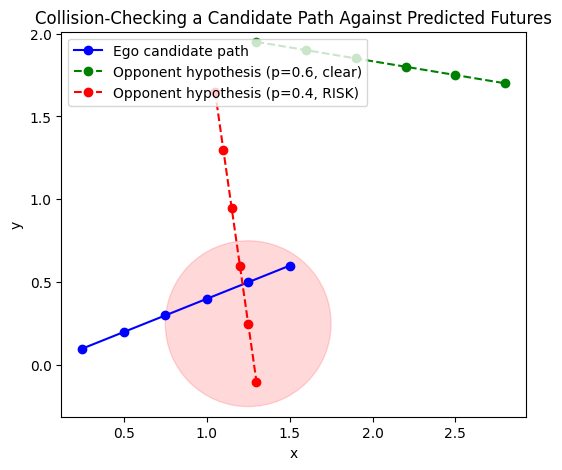


Expected collision probability: 0.40


In [ ]:
DT = 0.1
HORIZON = 6

# a candidate ego path: driving straight toward an alignment target
ego_start = np.array([0.0, 0.0])
ego_target = np.array([1.5, 0.6])
ego_velocity = (ego_target - ego_start) / (HORIZON * DT)
ego_path = np.array([ego_start + ego_velocity * DT * step for step in range(1, HORIZON + 1)])

# the opponent's predicted trajectory: two hypotheses, exactly the shape 07's
# multi-hypothesis model outputs; a probability plus a candidate path for each
opponent_hypotheses = [
    {"probability": 0.6, "path": np.array([[1.0 + 0.30 * s, 2.0 - 0.05 * s] for s in range(1, HORIZON + 1)])},  # passes well clear
    {"probability": 0.4, "path": np.array([[1.0 + 0.05 * s, 2.0 - 0.35 * s] for s in range(1, HORIZON + 1)])},  # cuts toward the ego path
]

SAFETY_RADIUS = 0.5

def closest_approach(path_a, path_b):
    distances = np.linalg.norm(path_a - path_b, axis=1)
    idx = np.argmin(distances)
    return distances[idx], idx

expected_collision_probability = 0.0
plt.figure(figsize=(6, 5))
plt.plot(ego_path[:, 0], ego_path[:, 1], "o-", color="blue", label="Ego candidate path")
colors = ["green", "red"]
for h, color in zip(opponent_hypotheses, colors):
    dist, idx = closest_approach(ego_path, h["path"])
    is_risk = dist < SAFETY_RADIUS
    if is_risk:
        expected_collision_probability += h["probability"]
    label = f"Opponent hypothesis (p={h['probability']:.1f}, {'RISK' if is_risk else 'clear'})"
    plt.plot(h["path"][:, 0], h["path"][:, 1], "o--", color=color, label=label)
    if is_risk:
        circle = plt.Circle(h["path"][idx], SAFETY_RADIUS, color=color, alpha=0.15)
        plt.gca().add_patch(circle)
    print(f"hypothesis (p={h['probability']:.1f}): closest approach = {dist:.2f} at t=+{(idx + 1) * DT:.1f}s -> risk={is_risk}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Collision-Checking a Candidate Path Against Predicted Futures")
plt.legend()
plt.axis("equal")
plt.show()

print(f"\nExpected collision probability: {expected_collision_probability:.2f}")

The hypothesis where the opponent continues on its current heading (probability 0.6) passes well clear. The hypothesis where it cuts toward the scoring area (probability 0.4) doesn't because its closest approach lands inside the safety radius. The resulting expected collision probability (0.4) is a single number a planner can act on. It is high enough to override the plan, even though it's *not* certain to happen. 

That's the value of carrying multiple weighted hypotheses instead of collapsing to one path. A single-hypothesis model would have given a false sense of certainty, either by predicting a collision that has a real 60% chance of not happening, or missing one that has a real 40% chance of happening.

## Closing the Loop: A Safety Override

The `collision_risk` argument on `AutoAlignFSM.step` above can be used for a safety override. Let's re-run a version of the earlier simulation, but this time feed in a real (if still synthetic) collision signal partway through, computed the same way as above, and watch it force an abort even though the tag stays confidently visible and the robot is mid-align.

In [ ]:
n_ticks = 40
fsm = AutoAlignFSM()
states = []
for t in range(n_ticks):
    driver_requesting = 5 <= t < 35
    tag_visible = True
    distance = max(0.5 - 0.02 * max(0, t - 5), 0.0)
    confidence = 0.9
    # a predicted collision risk that appears partway through; e.g. a new robot enters
    # frame with a predicted hypothesis that crosses our path, exactly the check above
    collision_risk = 15 <= t < 20
    states.append(fsm.step(driver_requesting, tag_visible, confidence, distance, collision_risk=collision_risk))

for t, s in enumerate(states):
    if t == 0 or states[t] != states[t - 1]:
        print(f"tick {t:>2}: -> {s}")

tick  0: -> IDLE
tick  5: -> ALIGNING
tick 15: -> IDLE
tick 20: -> ALIGNING
tick 28: -> ALIGNED
tick 35: -> IDLE


The state machine correctly aborts back to `IDLE` the instant a collision risk appears at tick 15. Note this happens even though the tag is still confidently visible and the robot was only moments from `ALIGNED`. 

Just as correctly, it resumes `ALIGNING` on its own the moment the risk clears at tick 20, without needing the driver to re-request anything. That's the whole point of building this as one state machine with a safety override, rather than two unrelated systems. The same decision logic that handles "the tag disappeared" also handles "something more urgent just appeared," and a real collision check from a real `07`-style prediction can drive it exactly the way this synthetic one just did.

## Try It Yourself

Using the auto-align simulation above, extend the occlusion window past the grace period (e.g. `18 <= t < 30`, a 12-tick occlusion against an 8-tick grace period) and re-run. Does the state machine give up and return to `IDLE`, and does it recover correctly once the tag reappears while the driver is still requesting?

Then, in the collision-checking example, swap the two opponent hypotheses' probabilities (`0.6`/`0.4` -> `0.2`/`0.8`) and re-run. How does the expected collision probability change? At what probability split would you want to set a `RISK_THRESHOLD` if you only wanted the robot to abort when a collision is more likely than not, rather than merely possible?

Finally, add a third opponent hypothesis to the collision-checking example (one that also passes clear, like the first) and update the expected-collision-probability sum to handle three hypotheses instead of two (a `for` loop over `opponent_hypotheses` instead of hardcoding two). Does adding a clear third hypothesis change the final decision?

## Resources

- [WPILib: Vision Processing](https://docs.wpilib.org/en/stable/docs/software/vision-processing/introduction/index.html) - the same overview linked from `02` and `03`; covers how a real auto-align pipeline reads Limelight/PhotonVision output into robot code.
- Khatib, O. (1986). "Real-Time Obstacle Avoidance for Manipulators and Mobile Robots." *The International Journal of Robotics Research*. The foundational collision-avoidance-as-a-planning-problem paper; `09-planning-and-av-context.ipynb` builds directly on this idea.
- Colledanchise, M. & Ögren, P. (2018). *Behavior Trees in Robotics and AI: An Introduction*. A more general alternative to hand-rolled state machines for exactly this kind of vision-triggered robot behavior, for teams who outgrow the FSM above.
- [LaValle, S. *Planning Algorithms*](http://lavalle.pl/planning/) - the standard reference for the broader motion-planning field this notebook's collision-checking is one small piece of; free online.